In [ ]:
import nltk
from nltk.corpus import brown
from nltk.tokenize import sent_tokenize, word_tokenize

nltk.download('brown')
nltk.download('punkt_tab')

news_text = brown.words(categories='news')

news_text_str = " ".join(news_text)

sentences = sent_tokenize(news_text_str)

words = word_tokenize(sentences[0])

print("First Sentence:\n", sentences[0])
print("\nTokenized Words from First Sentence:\n", words)


[nltk_data] Downloading package brown to /root/nltk_data...
[nltk_data]   Package brown is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


First Sentence:
 The Fulton County Grand Jury said Friday an investigation of Atlanta's recent primary election produced `` no evidence '' that any irregularities took place .

Tokenized Words from First Sentence:
 ['The', 'Fulton', 'County', 'Grand', 'Jury', 'said', 'Friday', 'an', 'investigation', 'of', 'Atlanta', "'s", 'recent', 'primary', 'election', 'produced', '``', 'no', 'evidence', '``', 'that', 'any', 'irregularities', 'took', 'place', '.']


In [ ]:
from nltk.corpus import stopwords
from nltk.probability import FreqDist

nltk.download('stopwords')

news_text = brown.words(categories='news')
news_text_str = " ".join(news_text)

words = word_tokenize(news_text_str)

words = [w.lower() for w in words if w.isalpha()]

stop_words = set(stopwords.words('english'))
filtered_words = [w for w in words if w not in stop_words]

fdist = FreqDist(filtered_words)

top_20 = fdist.most_common(20)

print("Top 20 words (without stopwords):")
for word, freq in top_20:
    print(f"{word}: {freq}")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Top 20 words (without stopwords):
said: 406
would: 249
new: 241
one: 214
last: 177
two: 174
state: 160
first: 158
year: 156
president: 154
home: 132
also: 129
made: 107
years: 104
time: 103
three: 101
city: 99
house: 99
week: 99
may: 93


In [ ]:
from nltk.stem import SnowballStemmer

news_text = brown.words(categories='news')
news_text_str = " ".join(news_text)

words = word_tokenize(news_text_str)

words = [w.lower() for w in words if w.isalpha()]

stop_words = set(stopwords.words('english'))
filtered_words = [w for w in words if w not in stop_words]

stemmer = SnowballStemmer("english")

stemmed_words = [stemmer.stem(w) for w in filtered_words]

fdist_stemmed = FreqDist(stemmed_words)

print("Top 20 Stemmed Words with Frequency:")
for word, freq in fdist_stemmed.most_common(20):
    print(f"{word}: {freq}")

Top 20 Stemmed Words with Frequency:
said: 406
year: 262
would: 249
new: 241
state: 229
one: 222
last: 179
two: 174
presid: 159
first: 158
home: 141
time: 133
also: 129
school: 129
week: 126
hous: 125
nation: 123
day: 117
member: 110
made: 107


In [ ]:
from nltk.stem import WordNetLemmatizer

nltk.download('wordnet')
nltk.download('omw-1.4')

news_text = brown.words(categories='news')
news_text_str = " ".join(news_text)

words = word_tokenize(news_text_str)

words = [w.lower() for w in words if w.isalpha()]

stop_words = set(stopwords.words('english'))
filtered_words = [w for w in words if w not in stop_words]

lemmatizer = WordNetLemmatizer()

lemmatized_words = [lemmatizer.lemmatize(w) for w in filtered_words]

fdist_lemmatized = FreqDist(lemmatized_words)

print("Top 20 Lemmatized Words with Frequency:")
for word, freq in fdist_lemmatized.most_common(20):
    print(f"{word}: {freq}")

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Top 20 Lemmatized Words with Frequency:
said: 406
year: 260
would: 249
new: 241
state: 223
one: 222
last: 177
two: 174
first: 158
president: 155
home: 141
also: 129
school: 127
week: 125
time: 123
day: 117
member: 110
made: 107
house: 106
city: 105


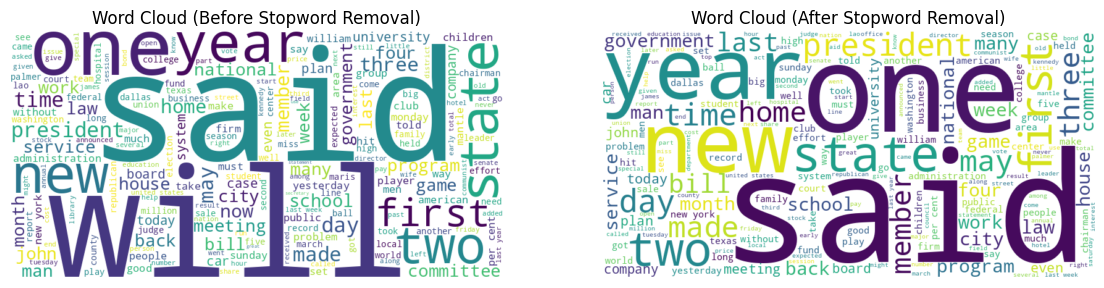

In [ ]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

news_text = brown.words(categories='news')
news_text_str = " ".join(news_text)

words = word_tokenize(news_text_str)

words = [w.lower() for w in words if w.isalpha()]

text_before = " ".join(words)
wc_before = WordCloud(width=800, height=400, background_color="white").generate(text_before)

stop_words = set(stopwords.words("english"))
filtered_words = [w for w in words if w not in stop_words]
text_after = " ".join(filtered_words)
wc_after = WordCloud(width=800, height=400, background_color="white").generate(text_after)

# ----- Plot both word clouds -----
plt.figure(figsize=(14, 6))

# Before
plt.subplot(1, 2, 1)
plt.imshow(wc_before, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud (Before Stopword Removal)")

# After
plt.subplot(1, 2, 2)
plt.imshow(wc_after, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud (After Stopword Removal)")

plt.show()